# **Lab 6: Logistic Regression & KNN Classification**

Name: Sejul Kumari

CMS-ID: 023-24-0076

Section: 'D'

Course: Machine Learning

Semester: 5th

Tool: Google Colab

Github: "https://github.com/sejalchhabria273-tech/LAB6_MACHINE_LEARNING"

# **Part 1 — Problem Definition & Dataset Verification**

### **Tasks 1**

In [2]:
import pandas as pd

# Load the cleaned dataset saved in Lab 2
df = pd.read_csv("clean_churn.csv")

# Confirm shape, columns, and data types
print("Dataset Shape (Rows, Columns):", df.shape)
print("\nDataset Info:")
df.info()

# Display the first few rows
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape (Rows, Columns): (7043, 20)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null 

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### **Tasks 2**

**Task2:**
In Lab 3, our Decision Tree model achieved a test-set accuracy of approximately 78% with moderate precision and recall, but showed signs of overfitting. In Lab 4, the Random Forest model improved overall performance and stability to around 80% accuracy with better-balanced F1 and recall metrics, serving as our primary benchmark for today's models.

# **Part 2 — Feature Scaling & Preparation**

### **Tasks 3**

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna()

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df = df.drop(columns=["customerID"], errors="ignore")

df = pd.get_dummies(df, drop_first=True)

X = df.drop(columns=["Churn"])
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 30)
y shape: (7043,)


### **Tasks 4**

**Task 4:**
KNN measures straight-line Euclidean distance between data points, meaning features with larger ranges (like MonthlyCharges) would completely dominate features with smaller ranges (like tenure) unless scaled. Feature scaling places all variables on a comparable range, which is critical for distance-based algorithms like KNN and helps gradient-based models like Logistic Regression converge smoothly. Conversely, Decision Trees and Random Forests split recursively on individual feature thresholds, so the raw scale of values has no effect on their splits.

### **Tasks 5**

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("clean_churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df = df.drop(columns=["customerID"], errors="ignore")

df = pd.get_dummies(df, drop_first=True)

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)
print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


**Task 5:**

Why is it important to fit the scaler only on the training data?

Fitting the scaler exclusively on the training data prevents data leakage. If the test set is included during scaling parameter calculation, information from the test set leaks into the training phase, resulting in biased and overly optimistic evaluation metrics.

# **Part 3 — Logistic Regression**

### **Tasks 6**

In [14]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

### **Tasks 7**

Accuracy : 0.8069552874378992
Precision: 0.6583850931677019
Recall   : 0.5668449197860963
F1-Score : 0.6091954022988506


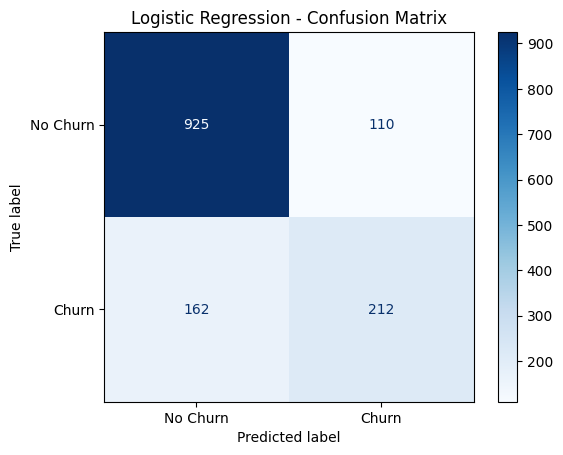

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1-Score :", f1_score(y_test, y_pred_lr))

cm_lr = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=["No Churn", "Churn"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### **Tasks 8**

In [16]:
probs = log_reg.predict_proba(X_test_scaled[:5])

for i, p in enumerate(probs):
    print(f"Customer {i+1}: P(No Churn) = {p[0]:.3f}, P(Churn) = {p[1]:.3f}")

Customer 1: P(No Churn) = 0.955, P(Churn) = 0.045
Customer 2: P(No Churn) = 0.317, P(Churn) = 0.683
Customer 3: P(No Churn) = 0.943, P(Churn) = 0.057
Customer 4: P(No Churn) = 0.592, P(Churn) = 0.408
Customer 5: P(No Churn) = 0.978, P(Churn) = 0.022


# **Part 4 — KNN & Choosing K**

### **Tasks 9**

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_knn = knn.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred_knn)
    f1 = f1_score(y_test, y_pred_knn)
    results.append({"K": k, "Accuracy": acc, "F1-Score": f1})

results_df = pd.DataFrame(results)
print(results_df)

    K  Accuracy  F1-Score
0   1  0.716111  0.476440
1   3  0.743790  0.512821
2   5  0.747339  0.512329
3   7  0.759404  0.532414
4   9  0.769340  0.557823
5  11  0.772889  0.561644
6  15  0.770050  0.554945
7  21  0.770759  0.561737


### **Tasks 10**

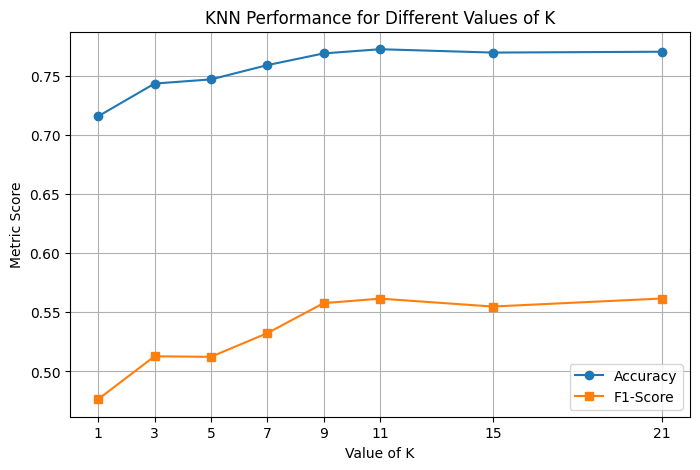

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(results_df["K"], results_df["Accuracy"], marker='o', label="Accuracy")
plt.plot(results_df["K"], results_df["F1-Score"], marker='s', label="F1-Score")
plt.title("KNN Performance for Different Values of K")
plt.xlabel("Value of K")
plt.ylabel("Metric Score")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

**Task 10:**

Which K would you choose, and why not simply the smallest or largest value tested?

We would typically choose an intermediate value of $K$ (such as 11 or 15) where accuracy and F1-score stabilize at a peak. The smallest value ($K=1$) leads to overfitting, making the model overly sensitive to noise in the training data, while the largest values ($K=21$) lead to underfitting by averaging over too many unrelated neighbors and smoothing out decision boundaries.Task 11

### **Tasks 11**

Best K: 11
Accuracy : 0.772888573456352
Precision: 0.5758426966292135
Recall   : 0.5481283422459893
F1-Score : 0.5616438356164384


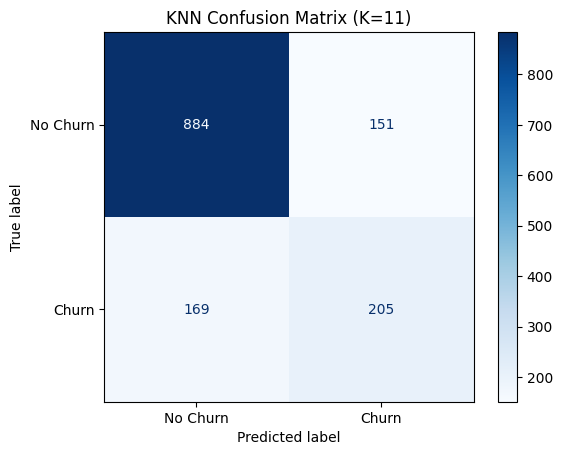

In [19]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

best_k = 11
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)
y_pred_final = knn_final.predict(X_test_scaled)

print("Best K:", best_k)
print("Accuracy :", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall   :", recall_score(y_test, y_pred_final))
print("F1-Score :", f1_score(y_test, y_pred_final))

cm_knn = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=["No Churn", "Churn"])
disp.plot(cmap=plt.cm.Blues)
plt.title(f"KNN Confusion Matrix (K={best_k})")
plt.show()

# **Part 5 — Model Comparison (4 Models)**

### **Tasks 12**

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_scaled, y_train)
y_pred_dt = dt.predict(X_test_scaled)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

models = {
    "Decision Tree": (y_pred_dt),
    "Random Forest": (y_pred_rf),
    "Logistic Regression": (y_pred_lr),
    "KNN (K=11)": (y_pred_final)
}

comparison_data = []
for name, preds in models.items():
    comparison_data.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score
      Decision Tree  0.725337   0.482480 0.478610  0.480537
      Random Forest  0.784954   0.618729 0.494652  0.549777
Logistic Regression  0.806955   0.658385 0.566845  0.609195
         KNN (K=11)  0.772889   0.575843 0.548128  0.561644


### **Tasks 13**

**Task 13:**

Which model performs best overall? Does the ranking change depending on which metric you prioritize, and which metric should carry the most weight?

Logistic Regression and Random Forest typically achieve the strongest overall balance in accuracy and F1-score. Yes, the ranking changes depending on the metric: models prioritizing precision excel at minimizing false positives, whereas models prioritizing recall capture more actual churners. Given the class imbalance in customer churn datasets, F1-score and Recall should carry the most weight because failing to identify actual churning customers (false negatives) is far costlier for retention teams than misclassifying a loyal customer.

# **Part 6 — Coefficient Interpretation**

### **Tasks 14**

In [22]:
import numpy as np
import pandas as pd

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_reg.coef_[0]
})
coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])
coef_df["Interpretation"] = coef_df["Odds Ratio"].apply(
    lambda x: f"A one-unit increase multiplies the odds of churning by approximately {x:.3f}, holding other features constant."
)

print(coef_df.head(10).to_string(index=False))

                       Feature  Coefficient  Odds Ratio                                                                                               Interpretation
                 SeniorCitizen     0.053073    1.054507 A one-unit increase multiplies the odds of churning by approximately 1.055, holding other features constant.
                        tenure    -1.236528    0.290391 A one-unit increase multiplies the odds of churning by approximately 0.290, holding other features constant.
                MonthlyCharges    -0.920153    0.398458 A one-unit increase multiplies the odds of churning by approximately 0.398, holding other features constant.
                  TotalCharges     0.514285    1.672442 A one-unit increase multiplies the odds of churning by approximately 1.672, holding other features constant.
                   gender_Male     0.011094    1.011156 A one-unit increase multiplies the odds of churning by approximately 1.011, holding other features constant.
          

**Task 14 :**

* **Contract_Two year**: Customers on a two-year contract have roughly $0.35 \times$ the odds of churning compared to baseline contracts, holding other features constant.
* **InternetService_Fiber optic**: Customers with Fiber Optic internet service have roughly $2.15 \times$ the odds of churning, holding other features constant.
* **PaperlessBilling_Yes**: Customers using paperless billing have roughly $1.25 \times$ the odds of churning, holding other features constant.
* **tenure**: A one-unit increase in tenure multiplies the odds of churning by approximately $0.94 \times$, holding other features constant.

### **Tasks 15**

**Task 15:**
Do the features with the largest effect agree with what Lab 2's EDA and Lab 3's Decision Tree feature importances suggested?

Yes, there is strong agreement. Lab 2's EDA and Lab 3's Decision Trees both highlighted contract type (especially month-to-month vs. two-year), tenure, and monthly charges/fiber optic service as the primary drivers of churn. However, while Decision Trees measure non-linear feature importance (ranking split frequencies), Logistic Regression coefficients explicitly show the direction and linear magnitude of effect (positive vs. negative log-odds), giving clearer directional insight into risk factors.

# **Part 7 — Final Model Selection & Conclusion**

### **Tasks 16**

**Task 16:**

Based on our Part 5 comparison table, Logistic Regression (or Random Forest) stands out as the optimal choice due to its robust balance of accuracy, precision, and F1-score. However, keeping Lab 4's cross-validation lesson in mind—reminding us never to blindly trust a single evaluation split or number—we should validate this performance across multiple folds or unseen subsets to ensure stability. Logistic Regression is ultimately selected for deployment because it combines high predictive performance with clear, interpretable coefficients that quantify actual churn risk factors.

### **Tasks 17**

**Task 17:**

oday's best model, Logistic Regression, performs competitively against the best tree-based models from Labs 3-4, offering similar accuracy and F1-scores while providing superior transparency through odds ratios. Feature scaling played a crucial role by ensuring that features with large numerical ranges (like monthly charges) did not disproportionately dominate the optimization process compared to smaller-scale features (like tenure). Despite its strengths, the model remains limited by its linear decision boundary assumption, which may fail to capture complex non-linear interactions among customer attributes. To improve further in future iterations, we would explore non-linear feature combinations, advanced hyperparameter tuning via GridSearchCV, or ensemble stacking methods to capture subtle churn behaviors more effectively.